# Step 1 – Descriptive landscape of the Quantum Computing sector (2010–2023)

This notebook starts from the output of **Step 0** (the list of DOCDB families that belong to the Quantum Computing sector) and describes the sector along five dimensions:

1. size of the sector (families and applications);
2. size of the families and grant status of the applications;
3. evolution over time, compared with the whole of PATSTAT;
4. technology mix (CPC subclasses and WIPO technology fields);
5. geography (filing offices, applicant and inventor countries).

No sector query is run again: every query below is restricted to the `docdb_family_id` list produced by Step 0.

**Time window.** The analysis covers families with first filing year between 2010 and 2023.
Applications are published about 18 months after filing, and PATSTAT is updated with a delay.
The last years (2021–2023) may therefore still be incomplete.
In every chart over time these years have a **grey background**.

## 0. Setup

Configuration, PATSTAT connection and two plotting helpers that are used in all the charts over time:
- `shade_incomplete` adds the grey background on the years that may be incomplete;
- `stacked_bars` draws one vertical bar per year, split into stacked colours (one colour per category).

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

ENV = "PROD"
SECTOR_NAME = "Quantum Computing"
from pathlib import Path

STEP0_NAME = f"qc_families_v2_{ENV}.csv"
_candidates = [Path.cwd() / "outputs" / "step0_epo" / STEP0_NAME]
_candidates += sorted(Path.cwd().rglob(STEP0_NAME)) + sorted(Path.home().rglob(STEP0_NAME))
STEP0_FILE = next((p for p in _candidates if p.exists()), None)
if STEP0_FILE is None:
    raise FileNotFoundError(f"{STEP0_NAME} non trovato sotto {Path.cwd()} né sotto {Path.home()}")
print("Step 0 file:", STEP0_FILE)
#STEP0_FILE = Path(f"outputs/step0_epo/qc_families_v2_{ENV}.csv")  # output of Step 0

IPR_TYPE = "PI"          # patents of invention only (no utility models)
START_YEAR, END_YEAR = 2010, 2023
INCOMPLETE_FROM = 2021   # from this year on the data may be incomplete
YEARS = list(range(START_YEAR, END_YEAR + 1))

patstat = PatstatClient(env=ENV)
db = patstat.orm()

Step 0 file: /home/s355199/Group15_innovation/outputs/step0_epo/qc_families_v2_PROD.csv


In [13]:
def shade_incomplete(ax):
    # Grey background on the years that may be incomplete
    ax.axvspan(INCOMPLETE_FROM - 0.5, END_YEAR + 0.5, color="grey", alpha=0.15, lw=0,
               label=f"possibly incomplete ({INCOMPLETE_FROM}-{END_YEAR})")
    ax.set_xlim(START_YEAR - 0.5, END_YEAR + 0.5)


def palette(columns):
    # tab10 colours, light grey for "Other"
    base = plt.get_cmap("tab10").colors
    return ["lightgrey" if c == "Other" else base[i % 10] for i, c in enumerate(columns)]


def stacked_bars(ax, table, title, ylabel, percent=False):
    # One vertical bar per year (rows), one stacked colour per category (columns)
    table = table.reindex(YEARS, fill_value=0)
    bottom = np.zeros(len(table))
    for col, colour in zip(table.columns, palette(table.columns)):
        ax.bar(table.index, table[col], bottom=bottom, color=colour, label=col,
               width=0.8, edgecolor="white", linewidth=0.3)
        bottom += table[col].to_numpy()
    shade_incomplete(ax)
    ax.set(title=title, xlabel="year", ylabel=ylabel)
    ax.set_xticks(YEARS)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    if percent:
        ax.set_ylim(0, 100)
        ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)


def to_shares(table):
    # Each row (year) sums to 100
    return table.div(table.sum(axis=1), axis=0).fillna(0) * 100

## 1. Sector families from Step 0

The family list is read from the Step 0 output file.
For each family the **family year** is the earliest filing year among its applications (`earliest_filing_year`, minimum over the family).
Only families with family year in 2010–2023 are kept: this list (`family_ids`) is the base of every query in the notebook.

In [14]:
def load_family_ids(path):
    # Parquet or csv: the first column holds the docdb_family_id
    df = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    return df.iloc[:, 0].dropna().astype("int64").unique().tolist()


step0_ids = load_family_ids(STEP0_FILE)

# Family year = earliest filing year of the family
fam_year = patstat.df(
    db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"),
             func.min(TLS201_APPLN.earliest_filing_year).label("year"))
    .filter(TLS201_APPLN.docdb_family_id.in_(step0_ids), TLS201_APPLN.ipr_type == IPR_TYPE)
    .group_by(TLS201_APPLN.docdb_family_id)
)
fam_year = fam_year[fam_year["year"].between(START_YEAR, END_YEAR)].reset_index(drop=True)
family_ids = fam_year["docdb_family_id"].astype("int64").tolist()

print(f"Families from Step 0: {len(step0_ids):,}")
print(f"Families with family year {START_YEAR}-{END_YEAR}: {len(family_ids):,}")

Families from Step 0: 12,177
Families with family year 2010-2023: 11,387


In [15]:
# Reusable filter and subquery restricted to the sector families
SECTOR_APPS = [TLS201_APPLN.docdb_family_id.in_(family_ids), TLS201_APPLN.ipr_type == IPR_TYPE]


def family_year_subquery():
    return (db.query(TLS201_APPLN.docdb_family_id.label("fid"),
                     func.min(TLS201_APPLN.earliest_filing_year).label("year"))
            .filter(*SECTOR_APPS)
            .group_by(TLS201_APPLN.docdb_family_id)
            .subquery())

## 2. Size of the sector

Number of families (inventions) and number of applications (patent filings) in the sector.
A family groups all the applications that protect the same invention in different offices.

In [16]:
total_families = len(family_ids)
total_patents = db.query(func.count(TLS201_APPLN.appln_id)).filter(*SECTOR_APPS).scalar()

print(f"Families (inventions): {total_families:,}")
print(f"Applications (patents): {total_patents:,}")

Families (inventions): 11,387
Applications (patents): 25,704


## 3. Family size

Number of applications in each family.
A larger family means that the invention is protected in more offices (a common proxy of the value the applicant gives to it).

In [17]:
df_family_size = patstat.df(
    db.query(TLS201_APPLN.docdb_family_id, func.count(TLS201_APPLN.appln_id).label("n_patents"))
    .filter(*SECTOR_APPS)
    .group_by(TLS201_APPLN.docdb_family_id)
)

size_table = (df_family_size["n_patents"].value_counts().sort_index()
              .rename_axis("n_patents_in_family").to_frame("n_families"))
size_table.loc["TOTAL"] = size_table["n_families"].sum()
display(size_table)

,n_families
n_patents_in_family,
1,6828
2,1440
3,1041
4,703
5,400
6,323
7,247
8,138
9,68


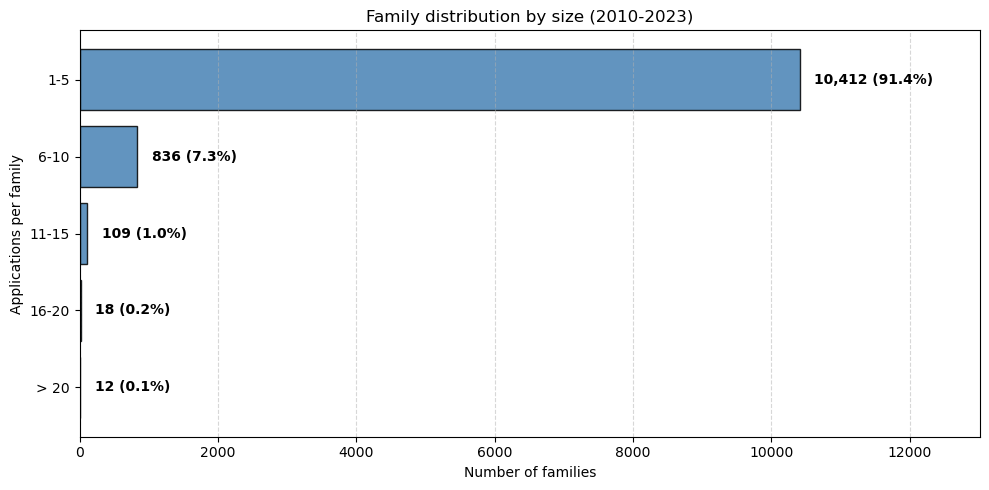

In [18]:
bins = [0, 5, 10, 15, 20, np.inf]
labels = ["1-5", "6-10", "11-15", "16-20", "> 20"]
buckets = (pd.cut(df_family_size["n_patents"], bins=bins, labels=labels)
           .value_counts().reindex(labels))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(buckets.index, buckets.values, color="steelblue", edgecolor="black", alpha=0.85)
for bar in bars:
    w = bar.get_width()
    ax.text(w + buckets.max() * 0.02, bar.get_y() + bar.get_height() / 2,
            f"{w:,} ({w / buckets.sum() * 100:.1f}%)", va="center", fontsize=10, fontweight="bold")
ax.set(title=f"Family distribution by size ({START_YEAR}-{END_YEAR})",
       xlabel="Number of families", ylabel="Applications per family",
       xlim=(0, buckets.max() * 1.25))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Grant status of the applications

Share of the sector applications that have been granted (`granted = Y`) or not (`granted = N`, which includes pending applications).
The count is at application level.

,granted,count,percentage
0,Y,12610,49.1
1,N,13094,50.9


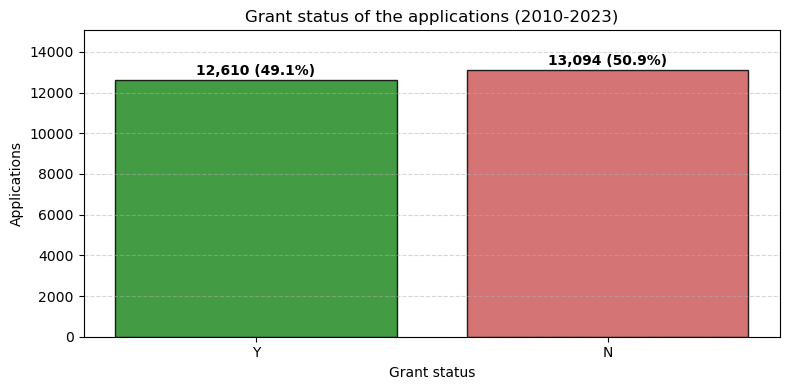

In [19]:
df_granted = patstat.df(
    db.query(TLS201_APPLN.granted, func.count(TLS201_APPLN.appln_id).label("count"))
    .filter(*SECTOR_APPS)
    .group_by(TLS201_APPLN.granted)
)
df_granted["granted"] = df_granted["granted"].fillna("Unknown")
df_granted["percentage"] = df_granted["count"] / df_granted["count"].sum() * 100
display(df_granted.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(df_granted["granted"], df_granted["count"],
              color=["forestgreen", "indianred", "gray"][:len(df_granted)], edgecolor="black", alpha=0.85)
for bar, pct in zip(bars, df_granted["percentage"]):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h * 1.01, f"{h:,} ({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set(title=f"Grant status of the applications ({START_YEAR}-{END_YEAR})",
       xlabel="Grant status", ylabel="Applications", ylim=(0, df_granted["count"].max() * 1.15))
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Families per year: sector vs all PATSTAT

Number of families per family year in the sector and in the whole of PATSTAT (same definition of family year, patents of invention only).
The table also gives the share of the sector on all families.
The chart shows the growth of each series with respect to 2010 (2010 = 0%).

In [20]:
# Sector: already known from Section 1
sector_year = fam_year.groupby("year").size()

# All PATSTAT families
fam_all = (db.query(TLS201_APPLN.docdb_family_id.label("fid"),
                    func.min(TLS201_APPLN.earliest_filing_year).label("year"))
           .filter(TLS201_APPLN.ipr_type == IPR_TYPE, TLS201_APPLN.docdb_family_id > 0)
           .group_by(TLS201_APPLN.docdb_family_id)
           .subquery())
all_year = patstat.df(
    db.query(fam_all.c.year, func.count().label("n"))
    .filter(fam_all.c.year.between(START_YEAR, END_YEAR))
    .group_by(fam_all.c.year)
).set_index("year")["n"]

yearly = pd.DataFrame({SECTOR_NAME: sector_year, "all patents": all_year}).reindex(YEARS).fillna(0)
yearly["share (%)"] = yearly[SECTOR_NAME] / yearly["all patents"] * 100
display(yearly)

,Quantum Computing,all patents,share (%)
year,,,
2010,76,1155701,0.006576
2011,54,1261794,0.004280
2012,72,1403316,0.005131
2013,100,1557918,0.006419
2014,130,1620696,0.008021
2015,182,1773771,0.010261
2016,256,1975437,0.012959
2017,385,2188660,0.017591
2018,666,2327825,0.028610


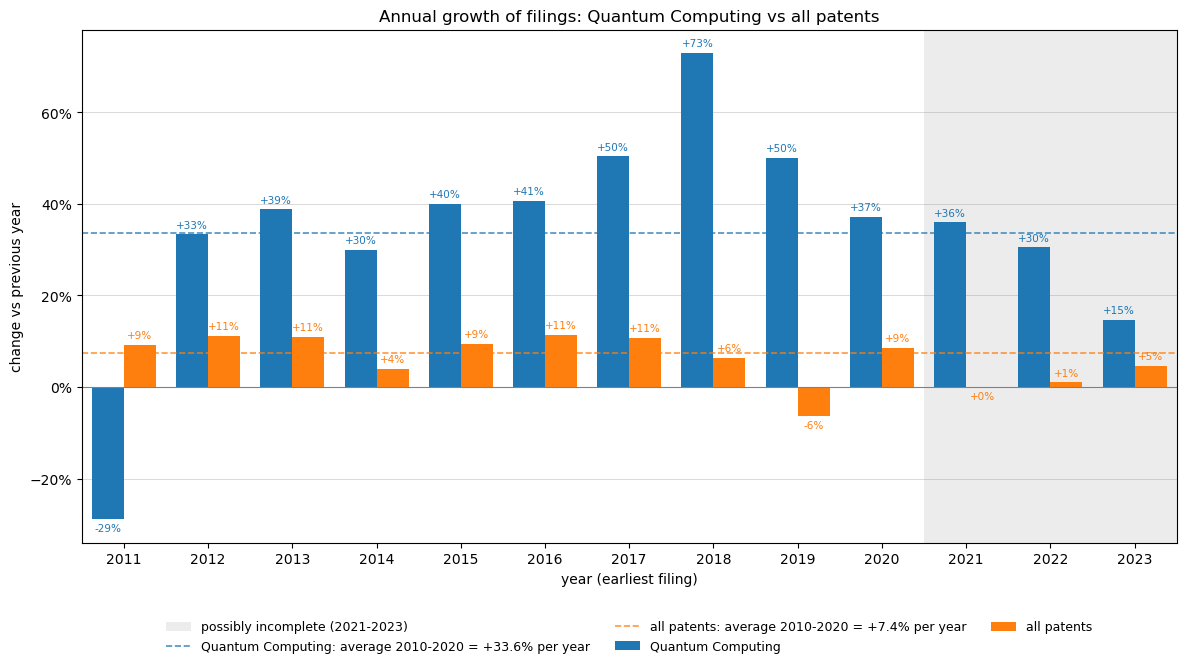

In [37]:
from matplotlib.ticker import PercentFormatter

cols = {SECTOR_NAME: "tab:blue", "all patents": "tab:orange"}
yoy  = yearly[list(cols)].astype(float).pct_change(fill_method=None).mul(100).loc[START_YEAR + 1:]
LAST_COMPLETE = INCOMPLETE_FROM - 1
n = LAST_COMPLETE - START_YEAR
avg = {c: ((yearly.loc[LAST_COMPLETE, c] / yearly.loc[START_YEAR, c]) ** (1 / n) - 1) * 100 for c in cols}

fig, ax = plt.subplots(figsize=(12, 6.8))
shade_incomplete(ax)                      # drawn first so it stays behind the bars
w = 0.38
for i, (c, colr) in enumerate(cols.items()):
    x = yoy.index + (i - 0.5) * w
    ax.bar(x, yoy[c], width=w, color=colr, label=c)
    for xi, v in zip(x, yoy[c]):
        ax.annotate(f"{round(v) + 0:+d}%", (xi, v), xytext=(0, 3 if v >= 0 else -3), textcoords="offset points",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=7.5, color=colr)
    ax.axhline(avg[c], color=colr, ls="--", lw=1.2, alpha=0.8,
               label=f"{c}: average {START_YEAR}-{LAST_COMPLETE} = {avg[c]:+.1f}% per year")

ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(START_YEAR + 0.5, END_YEAR + 0.5)
ax.set_xticks(yoy.index)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="y", color="lightgrey", lw=0.6)
ax.set_axisbelow(True)
ax.set(title=f"Annual growth of filings: {SECTOR_NAME} vs all patents",
       xlabel="year (earliest filing)", ylabel="change vs previous year")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

,CAGR 2010-2020 (%),CAGR 2010-2023 (%)
Quantum Computing,33.6,31.9
all patents,7.4,6.1
ratio sector / all,4.5,5.2


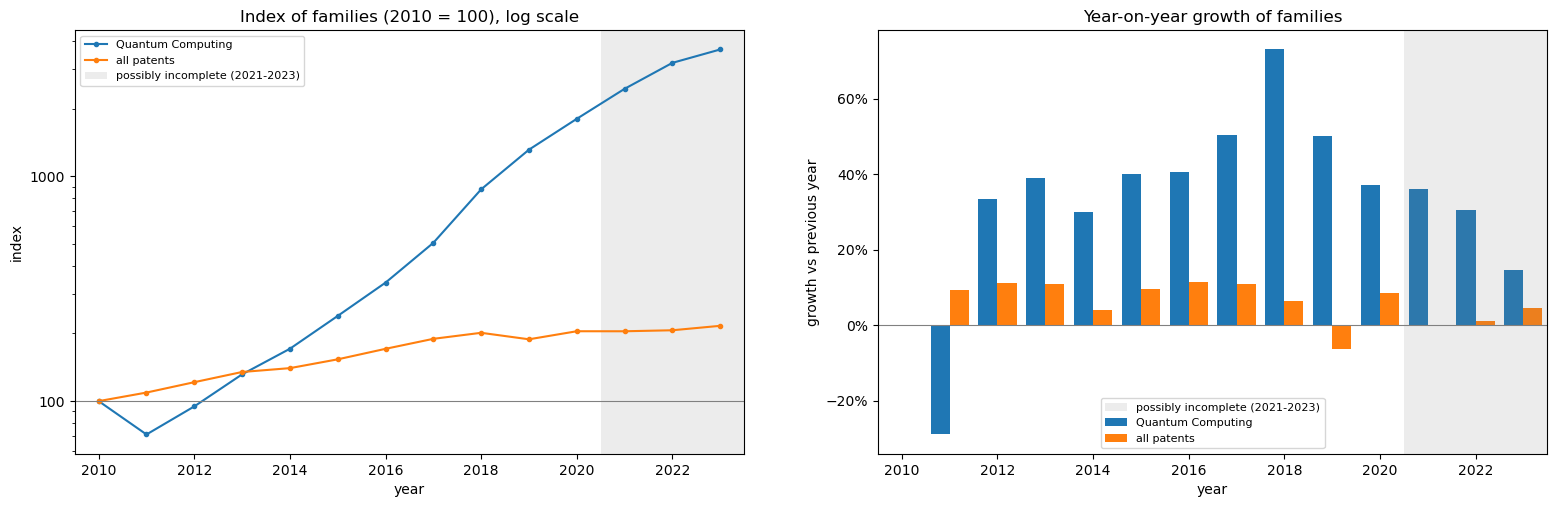

In [35]:
from matplotlib.ticker import PercentFormatter, ScalarFormatter, NullFormatter

cols = [SECTOR_NAME, "all patents"]
counts = yearly[cols].astype(float)
LAST_COMPLETE = INCOMPLETE_FROM - 1

# (a) index, START_YEAR = 100 -> plotted on a log scale (equal slope = equal growth rate)
index = counts / counts.loc[START_YEAR] * 100
# (b) year-on-year growth rate (%)
yoy = counts.pct_change(fill_method=None) * 100
# (c) compound annual growth rate (CAGR)
def cagr(s, y0, y1):
    return ((s.loc[y1] / s.loc[y0]) ** (1 / (y1 - y0)) - 1) * 100

cagr_table = pd.DataFrame({
    f"CAGR {START_YEAR}-{LAST_COMPLETE} (%)": [cagr(counts[c], START_YEAR, LAST_COMPLETE) for c in cols],
    f"CAGR {START_YEAR}-{END_YEAR} (%)":      [cagr(counts[c], START_YEAR, END_YEAR) for c in cols],
}, index=cols).round(1)
cagr_table.loc["ratio sector / all"] = (cagr_table.loc[SECTOR_NAME] / cagr_table.loc["all patents"]).round(1)
display(cagr_table)

fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))

# (a) index on log scale
ax = axes[0]
for c in cols:
    ax.plot(index.index, index[c], marker="o", ms=3, label=c)
ax.axhline(100, color="grey", lw=0.8)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())
shade_incomplete(ax)
ax.set(title=f"Index of families ({START_YEAR} = 100), log scale", xlabel="year", ylabel="index")
ax.legend(fontsize=8)

# (b) year-on-year growth, grouped bars
ax = axes[1]
w = 0.4
for i, c in enumerate(cols):
    ax.bar(yoy.index + (i - 0.5) * w, yoy[c], width=w, label=c)
ax.axhline(0, color="grey", lw=0.8)
shade_incomplete(ax)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(title="Year-on-year growth of families", xlabel="year", ylabel="growth vs previous year")
ax.legend(fontsize=8)



## 6. Technology mix – CPC subclasses

**What a sub-field is.** The Cooperative Patent Classification (CPC) is hierarchical: section (1 letter, e.g. `G` Physics) → class (3 characters, e.g. `G06` Computing) → **subclass (4 characters, e.g. `G06N`)** → group (e.g. `G06N 10/00`).
Here a *sub-field* is a CPC **subclass**, i.e. the first 4 characters of the CPC symbols of the applications.
For each family the subclasses of all its applications are collected.

The subclasses that recur most often in this sector are:

| Subclass | Title (CPC) |
|---|---|
| G06N | Computing arrangements based on specific computational models (incl. `G06N 10/00` quantum computing) |
| G06F | Electric digital data processing |
| H04L | Transmission of digital information (incl. quantum key distribution, `H04L 9/0852`) |
| H04B | Transmission (incl. quantum communication, `H04B 10/70`) |
| B82Y | Specific uses or applications of nanostructures (incl. `B82Y 10/00` quantum computing) |
| H10N | Electric solid-state devices not otherwise provided for (incl. superconducting devices) |
| H10D | Inorganic electric semiconductor devices |
| Y02D | Climate change mitigation technologies in information and communication technologies |

**Counting.** Fractional counting: a family classified in *k* subclasses gives 1/*k* to each, so every family counts 1 in total.
Only the most frequent subclasses over 2010–2023 are shown, the others are grouped in "Other".

Outputs:
- a table with the weight of each subclass over the period and its share in the first and last year;
- a table with the subclass that grows most (in families) each year;
- stacked bars per year, in number of families and in share of the sector.

In [23]:
TOP_N = 8  # subclasses shown, the others go to "Other"

CPC_TITLES = {
    "G06N": "Computing models (incl. quantum computing)",
    "G06F": "Electric digital data processing",
    "H04L": "Transmission of digital information",
    "H04B": "Transmission",
    "B82Y": "Nanostructures (uses, measurement, manufacture)",
    "H10N": "Solid-state devices n.o.p. (incl. superconducting)",
    "H10D": "Inorganic semiconductor devices",
    "Y02D": "Climate change mitigation in ICT",
    "H01L": "Semiconductor devices",
    "G01R": "Measuring electric/magnetic variables",
    "G02F": "Optical devices controlling light",
    "H03K": "Pulse technique",
    "G01N": "Investigating materials (chemical/physical)",
    "H01P": "Waveguides, resonators",
    "H03M": "Coding, decoding",
    "G06E": "Optical computing devices",
}

subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
fam = family_year_subquery()

# Distinct (family, subclass) pairs over all applications of the family
pairs = (db.query(fam.c.fid, fam.c.year, subclass.label("subclass"))
         .select_from(fam)
         .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == fam.c.fid)
         .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
         .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
         .distinct().subquery())

# Fractional count: a family in k subclasses gives 1/k to each
k = db.query(pairs.c.fid, func.count().label("k")).group_by(pairs.c.fid).subquery()
cpc = patstat.df(
    db.query(pairs.c.subclass, pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
    .join(k, k.c.fid == pairs.c.fid)
    .group_by(pairs.c.subclass, pairs.c.year)
)

wide = cpc.pivot_table(index="year", columns="subclass", values="n_frac",
                       aggfunc="sum", fill_value=0).reindex(YEARS, fill_value=0)
top = list(wide.sum().nlargest(TOP_N).index)
cpc_wide = wide[top].assign(Other=wide.drop(columns=top).sum(axis=1))
cpc_shares = to_shares(cpc_wide)

print("Subclasses shown:")
for s in top:
    print(f"  {s}: {CPC_TITLES.get(s, '(title not in the list above)')}")

Subclasses shown:
  G06N: Computing models (incl. quantum computing)
  G06F: Electric digital data processing
  H04L: Transmission of digital information
  B82Y: Nanostructures (uses, measurement, manufacture)
  H10N: Solid-state devices n.o.p. (incl. superconducting)
  Y02D: Climate change mitigation in ICT
  H04B: Transmission
  G06Q: (title not in the list above)


In [24]:
# Table 1: weight of each subclass over the period, share in the first and last year
summary = pd.DataFrame({
    f"families {START_YEAR}-{END_YEAR} (frac.)": cpc_wide.sum(),
    f"share {START_YEAR} (%)": cpc_shares.loc[START_YEAR],
    f"share {END_YEAR} (%)": cpc_shares.loc[END_YEAR],
    "Δ share (p.p.)": cpc_shares.loc[END_YEAR] - cpc_shares.loc[START_YEAR],
}).sort_values("Δ share (p.p.)", ascending=False)
display(summary.round(1))

# Table 2: subclass with the largest increase of families vs the previous year
diff = cpc_wide[top].diff().loc[START_YEAR + 1:]
display(pd.DataFrame({"fastest growing subclass": diff.idxmax(axis=1),
                      "increase vs previous year (families)": diff.max(axis=1).round(1)}))

,families 2010-2023 (frac.),share 2010 (%),share 2023 (%),Δ share (p.p.)
subclass,,,,
G06N,4681.7,16.7,52.7,36.0
Y02D,269.6,0.0,4.0,4.0
H04L,868.3,4.0,5.8,1.9
G06F,1226.9,7.6,8.6,1.0
H10N,424.3,6.0,3.8,-2.2
H04B,254.5,4.0,1.5,-2.4
G06Q,183.3,4.7,1.7,-3.0
Other,2278.4,36.0,18.6,-17.4
B82Y,437.0,21.1,3.1,-18.0


,fastest growing subclass,increase vs previous year (families)
year,,
2011,H04L,0.8
2012,G06N,3.1
2013,G06N,16.2
2014,G06Q,4.2
2015,G06N,14.9
2016,H04L,30.3
2017,G06N,30.5
2018,G06N,70.2
2019,G06N,135.2


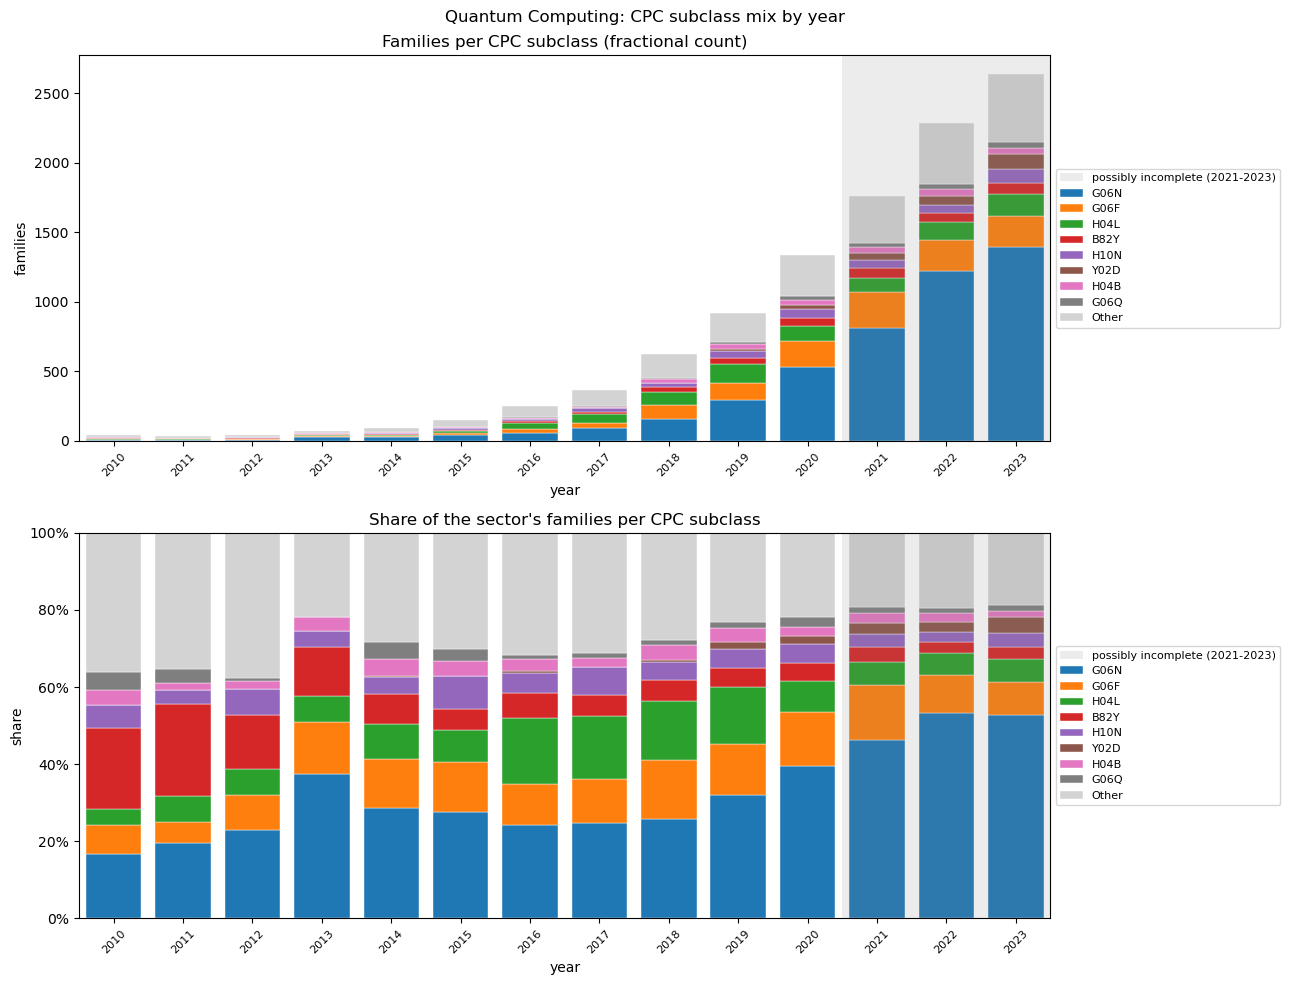

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
stacked_bars(axes[0], cpc_wide, "Families per CPC subclass (fractional count)", "families")
stacked_bars(axes[1], cpc_shares, "Share of the sector's families per CPC subclass", "share", percent=True)
fig.suptitle(f"{SECTOR_NAME}: CPC subclass mix by year")
plt.tight_layout()
plt.show()

## 7. Technology mix – WIPO technology fields

**What the sub-fields are.** The WIPO IPC–Technology Concordance (Schmoch, 2008) maps IPC codes into **35 technology fields**, grouped into **5 technology sectors**: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields.
PATSTAT gives, for each application, the fields it belongs to with a weight (table `TLS230_APPLN_TECHN_FIELD`); the names come from `TLS901_TECHN_FIELD_IPC`.

**Counting.** For each family the weights of all its applications are summed by field and rescaled so that the family counts 1 in total (fractional counting).
Results are shown for the 5 sectors and for the most frequent fields ("Other" groups the rest), first over the whole period and then year by year as stacked bars.

In [26]:
TOP_N_FIELDS = 8
T230 = TLS230_APPLN_TECHN_FIELD
fam = family_year_subquery()

# Weight of each field in each family (sum of the TLS230 weights of its applications)
ff = (db.query(fam.c.fid, fam.c.year, T230.techn_field_nr, func.sum(T230.weight).label("w"))
      .select_from(fam)
      .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == fam.c.fid)
      .join(T230, T230.appln_id == TLS201_APPLN.appln_id)
      .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
      .group_by(fam.c.fid, fam.c.year, T230.techn_field_nr)
      .subquery())

# Rescaling: the weights of each family sum to 1
tot = db.query(ff.c.fid, func.sum(ff.c.w).label("wt")).group_by(ff.c.fid).subquery()
fields = patstat.df(
    db.query(ff.c.year, ff.c.techn_field_nr, func.sum(ff.c.w / tot.c.wt).label("n_frac"))
    .join(tot, tot.c.fid == ff.c.fid)
    .group_by(ff.c.year, ff.c.techn_field_nr)
)

# Names of the 35 fields and 5 sectors
names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")
names[["techn_field", "techn_sector"]] = names[["techn_field", "techn_sector"]].apply(lambda s: s.str.strip())
fields = fields.merge(names, on="techn_field_nr", how="left")

top_fields = list(fields.groupby("techn_field")["n_frac"].sum().nlargest(TOP_N_FIELDS).index)
fields["field"] = fields["techn_field"].where(fields["techn_field"].isin(top_fields), "Other")

In [27]:
def share_table(counts):
    # Counts -> shares (%), "Other" last, plus a "Total" row
    shares = (counts / counts.sum() * 100).sort_values(ascending=False)
    order = [i for i in shares.index if i != "Other"] + (["Other"] if "Other" in shares.index else [])
    shares = shares.loc[order].to_frame("share of families (%)")
    shares.loc["Total"] = shares.sum()
    return shares.round(1)


# Whole period: 5 sectors and top fields
display(share_table(fields.groupby("techn_sector")["n_frac"].sum()))
display(share_table(fields.groupby("field")["n_frac"].sum()))

,share of families (%)
techn_sector,
Electrical engineering,89.5
Instruments,5.9
Chemistry,3.3
Mechanical engineering,1.1
Other fields,0.2
Total,100.0


,share of families (%)
field,
Computer technology,61.8
Digital communication,9.8
Semiconductors,8.8
Telecommunications,3.4
Optics,2.5
Basic communication processes,2.4
Measurement,2.3
Micro-structural and nano-technology,2.1
Other,6.8


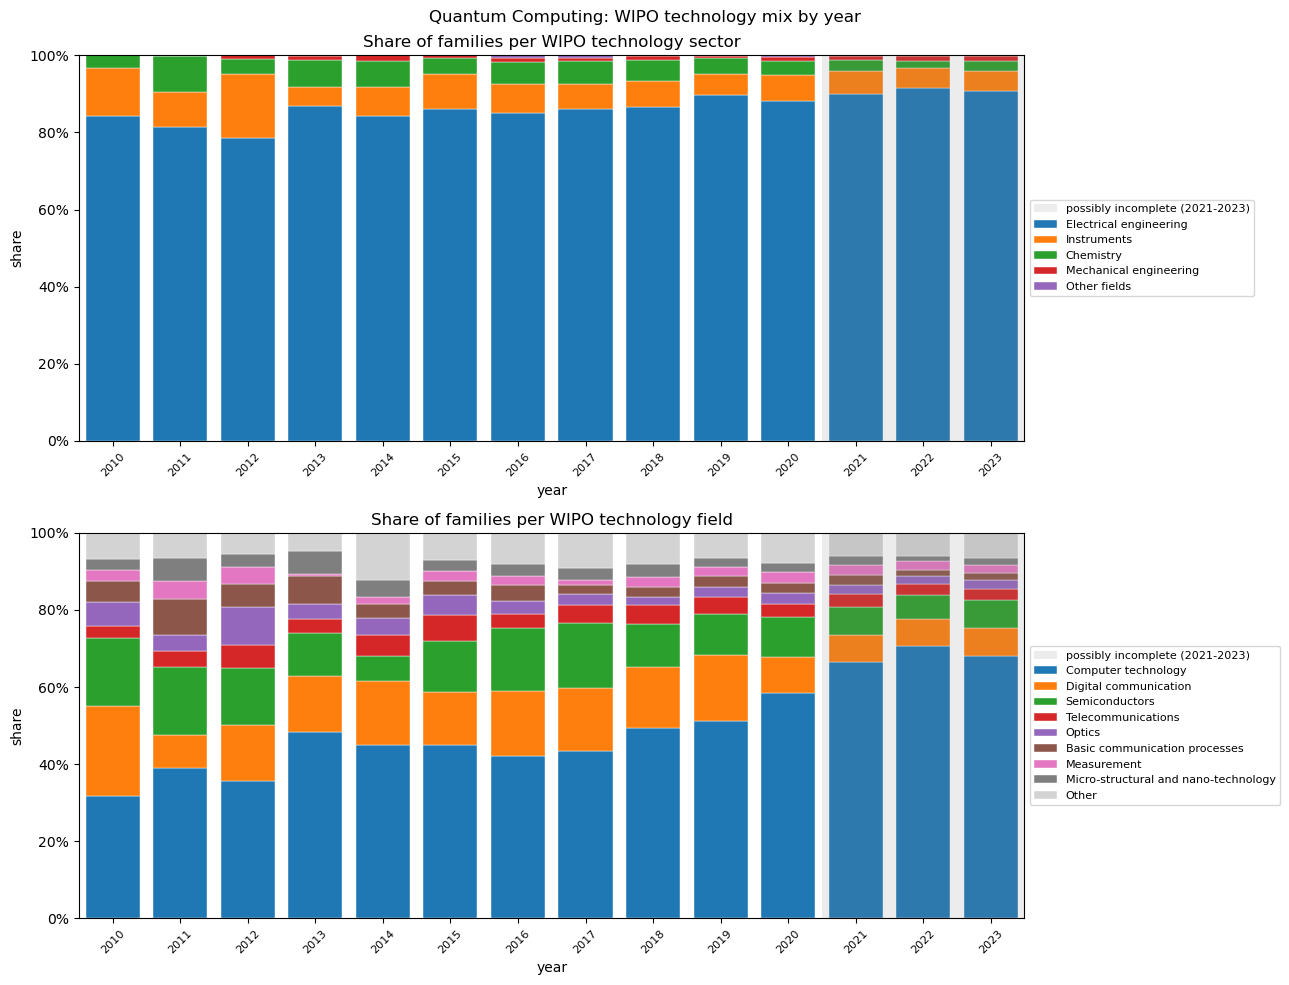

In [28]:
sector_y = fields.pivot_table(index="year", columns="techn_sector", values="n_frac", aggfunc="sum", fill_value=0)
sector_y = to_shares(sector_y[sector_y.sum().sort_values(ascending=False).index])

field_y = (fields.pivot_table(index="year", columns="field", values="n_frac", aggfunc="sum", fill_value=0)
           .reindex(columns=top_fields + ["Other"], fill_value=0))
field_y = to_shares(field_y)

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
stacked_bars(axes[0], sector_y, "Share of families per WIPO technology sector", "share", percent=True)
stacked_bars(axes[1], field_y, "Share of families per WIPO technology field", "share", percent=True)
fig.suptitle(f"{SECTOR_NAME}: WIPO technology mix by year")
plt.tight_layout()
plt.show()

## 8. Geography

The analysis is at **application** level (applications of the sector families filed in 2010–2023).

- **Filing offices.** Office where each application is filed (`appln_auth`). The IP5 offices are EP, US, CN, JP, KR; `WO` are PCT international applications.
- **Applicant and inventor countries.** Country of the persons linked to each application (`TLS206`/`TLS207`). The applicant country is a proxy of who **owns** the technology, the inventor country of where the **R&D** is done. Each application is split among its distinct persons with a known country (fractional counting). Applications without any known country are excluded; the coverage is printed.

In [29]:
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")
TOP_N_CTRY = 5
APPS_IN_WINDOW = SECTOR_APPS + [TLS201_APPLN.appln_filing_year.between(START_YEAR, END_YEAR)]

# Filing offices
off = patstat.df(
    db.query(TLS201_APPLN.appln_auth.label("office"),
             TLS201_APPLN.appln_filing_year.label("year"),
             func.count().label("n"))
    .filter(*APPS_IN_WINDOW)
    .group_by(TLS201_APPLN.appln_auth, TLS201_APPLN.appln_filing_year)
)
off["office"] = off["office"].str.strip()
off["office"] = off["office"].where(off["office"].isin(IP5_OFFICES + ("WO",)), "Other")
total_apps = off["n"].sum()

office_tab = (off.groupby("office")["n"].sum()
              .reindex(list(IP5_OFFICES) + ["WO", "Other"], fill_value=0).to_frame("applications"))
office_tab["share (%)"] = office_tab["applications"] / total_apps * 100
office_tab.loc["Total"] = office_tab.sum()
print(f"Share of applications filed at the IP5 offices: "
      f"{office_tab.loc[list(IP5_OFFICES), 'share (%)'].sum():.1f}%")
display(office_tab.round(1))

Share of applications filed at the IP5 offices: 74.6%


,applications,share (%)
office,,
EP,2526.0,11.0
US,5929.0,25.7
CN,6054.0,26.3
JP,1839.0,8.0
KR,849.0,3.7
WO,2999.0,13.0
Other,2859.0,12.4
Total,23055.0,100.0


In [30]:
def country_by_role(role):
    # Each application is split among its distinct persons with a known country (sum 1)
    seq = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)
    persons = (db.query(TLS201_APPLN.appln_id.label("aid"),
                        TLS201_APPLN.appln_filing_year.label("year"),
                        TLS207_PERS_APPLN.person_id, ctry.label("ctry"))
               .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
               .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
               .filter(*APPS_IN_WINDOW, seq > 0, ctry.isnot(None), ctry != "")
               .distinct().subquery())
    k = db.query(persons.c.aid, func.count().label("k")).group_by(persons.c.aid).subquery()
    q = (db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
         .join(k, k.c.aid == persons.c.aid)
         .group_by(persons.c.ctry, persons.c.year))
    return patstat.df(q).assign(role=role)


countries = pd.concat([country_by_role("applicant"), country_by_role("inventor")], ignore_index=True)

for role in ("applicant", "inventor"):
    cov = countries.query("role == @role")["n_frac"].sum() / total_apps * 100
    print(f"Applications with a known {role} country: {cov:.1f}%")

cc = countries.pivot_table(index="ctry", columns="role", values="n_frac", aggfunc="sum", fill_value=0)[["applicant", "inventor"]]
top_ctry = list(cc["applicant"].nlargest(TOP_N_CTRY).index)
cc = cc.groupby(cc.index.where(cc.index.isin(top_ctry), "Other")).sum().reindex(top_ctry + ["Other"], fill_value=0)
ctry_shares = cc / cc.sum() * 100
ctry_shares.loc["Total"] = ctry_shares.sum()
display(ctry_shares.round(1).rename(columns={"applicant": "applicant share (%)", "inventor": "inventor share (%)"}))

Applications with a known applicant country: 64.5%
Applications with a known inventor country: 58.3%


role,applicant share (%),inventor share (%)
ctry,,
US,51.7,48.9
JP,6.5,7.0
CN,5.5,5.6
DE,5.0,5.1
CA,4.9,5.3
Other,26.5,28.1
Total,100.0,100.0


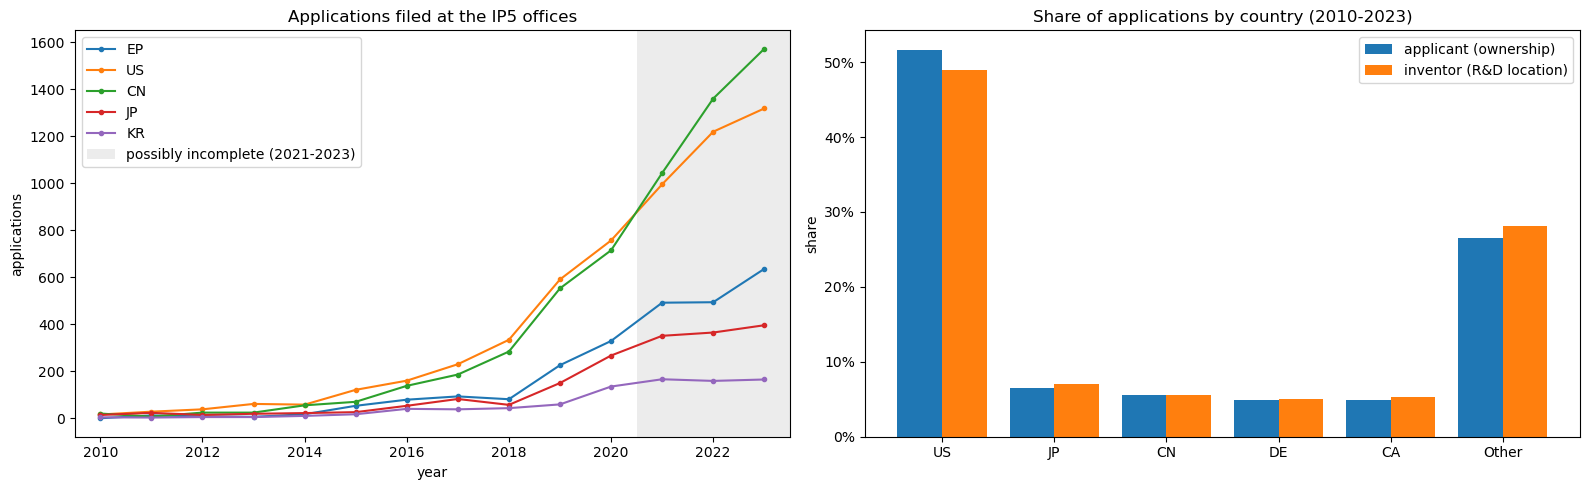

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Applications per year at each IP5 office
off_y = (off.pivot_table(index="year", columns="office", values="n", aggfunc="sum", fill_value=0)
         .reindex(YEARS, fill_value=0))
for o in IP5_OFFICES:
    if o in off_y.columns:
        axes[0].plot(off_y.index, off_y[o], marker="o", ms=3, label=o)
shade_incomplete(axes[0])
axes[0].set(title="Applications filed at the IP5 offices", xlabel="year", ylabel="applications")
axes[0].legend()

# Applicant vs inventor share per country, whole period
plot = ctry_shares.drop("Total")
x = np.arange(len(plot))
axes[1].bar(x - 0.2, plot["applicant"], 0.4, label="applicant (ownership)")
axes[1].bar(x + 0.2, plot["inventor"], 0.4, label="inventor (R&D location)")
axes[1].set_xticks(x, plot.index)
axes[1].set(title=f"Share of applications by country ({START_YEAR}-{END_YEAR})", ylabel="share")
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].legend()

plt.tight_layout()
plt.show()

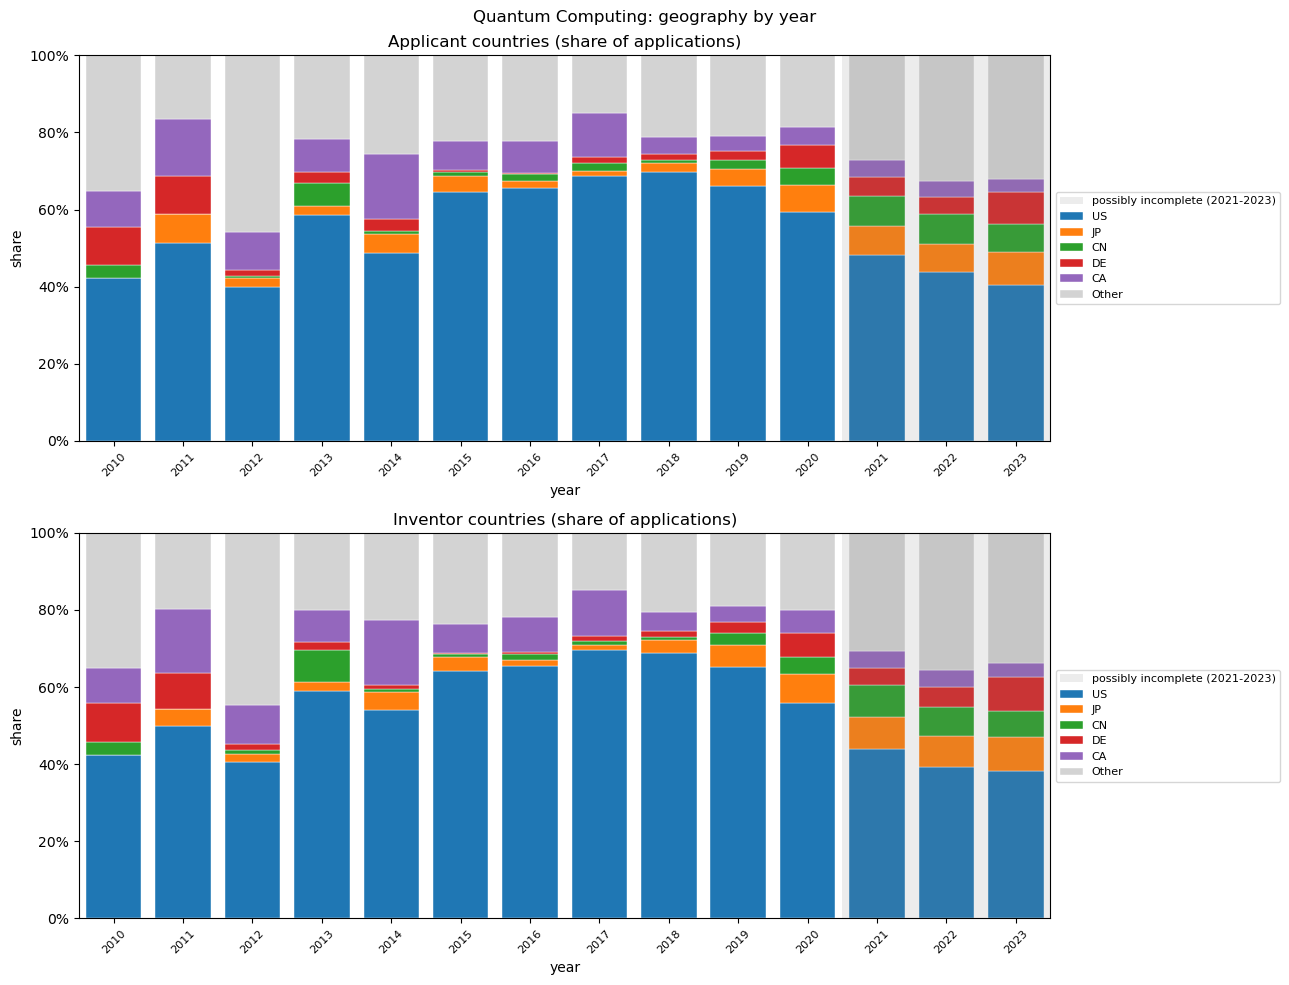

In [32]:
# Applicant and inventor countries year by year (stacked bars)
countries["ctry_p"] = countries["ctry"].where(countries["ctry"].isin(top_ctry), "Other")

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, role in zip(axes, ("applicant", "inventor")):
    w = (countries.query("role == @role")
         .pivot_table(index="year", columns="ctry_p", values="n_frac", aggfunc="sum", fill_value=0)
         .reindex(columns=top_ctry + ["Other"], fill_value=0))
    stacked_bars(ax, to_shares(w), f"{role.capitalize()} countries (share of applications)", "share", percent=True)
fig.suptitle(f"{SECTOR_NAME}: geography by year")
plt.tight_layout()
plt.show()